<a href="https://colab.research.google.com/github/Anyangos/Digital-Twin/blob/RAG/Week2_09_rag_101_retrieval_systems.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 2.4: RAG 101 - Retrieval Systems

## Key Insight
> **The pipeline: Load → Split → Embed → Retrieve → Answer**

## Learning Objectives
By the end of this notebook, you will:
- RAG architecture and pipeline
- Document loading and preprocessing
- Chunking strategies for optimal retrieval
- Vector stores and similarity search
- Generating answers with retrieved context

## Exercises
This notebook contains 4 exercises ranging from easy to advanced.

## Digital Twin Integration
This notebook extends your digital twin with production-ready capabilities from Week 2.

In [ ]:
# Setup and imports
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from typing import List, Dict, Any, Tuple
import re
import json

print('✅ Week 2.4: RAG 101 - Retrieval Systems - Ready to start!')
print('\nTopics covered:')
print('  - RAG architecture and pipeline')
print('  - Document loading and preprocessing')
print('  - Chunking strategies for optimal retrieval')
print('  - Vector stores and similarity search')
print('  - Generating answers with retrieved context')


---
## Part 1: Introduction to RAG architecture and pipeline

Let's start by understanding the fundamentals and building our first implementation.

In [ ]:
# Example implementation
# This is a starter template - expand with your implementation

class ExampleClass:
    """
    Example class for RAG architecture and pipeline.
    """

    def __init__(self):
        self.data = []

    def process(self, input_data):
        """
        Process the input data.
        """
        # Add your implementation here
        return input_data

# Test the class
example = ExampleClass()
result = example.process('test data')
print(f'Result: {result}')

### 🎯 Exercise 1 (Easy): Getting Started

**Task**: Implement a basic version of the concept introduced above.

**Requirements**:
1. Follow the pattern shown in the example
2. Test your implementation with sample data
3. Verify the output matches expectations
4. Add error handling for edge cases

In [2]:
from typing import List

class SimpleRAGPipeline:
    def __init__(self):
        self.documents = []
        self.chunks = []

    def load_documents(self, docs: List[str]):
        """Stage 1: Load documents"""
        if not docs:
            raise ValueError("Documents list cannot be empty!")
        self.documents = docs
        print(f"Loaded {len(self.documents)} documents.")

    def split_documents(self):
        """Stage 2: Split documents into sentence chunks"""
        self.chunks = []
        for doc in self.documents:
            # Split by simple period punctuation
            sentences = [s.strip() for s in doc.split('.') if s.strip()]
            self.chunks.extend(sentences)
        print(f"Split documents into {len(self.chunks)} chunks.")

    def retrieve(self, query: str, top_k: int = 2) -> List[str]:
        """Stage 3 & 4: Embed & Retrieve (Naive keyword similarity for this starter exercise)"""
        query_words = set(query.lower().split())
        scored_chunks = []

        for chunk in self.chunks:
            chunk_words = set(chunk.lower().split())
            # Calculate simple Jaccard-like overlap as our similarity score
            overlap = len(query_words.intersection(chunk_words))
            scored_chunks.append((overlap, chunk))

        # Sort by overlap score descending
        scored_chunks.sort(key=lambda x: x[0], reverse=True)

        # Return top K chunks that have at least some match, or fallback to top K
        return [chunk for score, chunk in scored_chunks[:top_k] if score > 0]

    def answer(self, query: str) -> str:
        """Stage 5: Answer based on retrieved context"""
        retrieved_context = self.retrieve(query)

        if not retrieved_context:
            return "I couldn't find any relevant context in my loaded documents to answer that query."

        context_str = " ".join(retrieved_context)
        response = f"[System Answer grounded in context]: Based on '{context_str}', here is your answer to: '{query}'"
        return response

# --- Test Cases & Verification ---
try:
    # 1. Initialize pipeline
    rag = SimpleRAGPipeline()

    # 2. Load sample documents
    documents = [
        "RAG stands for Retrieval-Augmented Generation. It combines retrievers and generators.",
        "Python is an interpreted high-level general-purpose programming language. It supports OOP.",
        "Vector databases are designed to store and query high-dimensional vector embeddings efficiently."
    ]
    rag.load_documents(documents)

    # 3. Split documents
    rag.split_documents()

    # 4. Test Query 1 (RAG Topic)
    print("\n--- Query 1 ---")
    query1 = "What does RAG stand for?"
    print(f"User: {query1}")
    print(rag.answer(query1))

    # 5. Test Query 2 (Database Topic)
    print("\n--- Query 2 ---")
    query2 = "Tell me about vector databases"
    print(f"User: {query2}")
    print(rag.answer(query2))

    # 6. Test Edge Case (No match found)
    print("\n--- Query 3 (Edge Case) ---")
    query3 = "What is the capital of France?"
    print(f"User: {query3}")
    print(rag.answer(query3))

except Exception as e:
    print(f"An error occurred: {e}")

Loaded 3 documents.
Split documents into 5 chunks.

--- Query 1 ---
User: What does RAG stand for?
[System Answer grounded in context]: Based on 'RAG stands for Retrieval-Augmented Generation', here is your answer to: 'What does RAG stand for?'

--- Query 2 ---
User: Tell me about vector databases
[System Answer grounded in context]: Based on 'Vector databases are designed to store and query high-dimensional vector embeddings efficiently', here is your answer to: 'Tell me about vector databases'

--- Query 3 (Edge Case) ---
User: What is the capital of France?
[System Answer grounded in context]: Based on 'Python is an interpreted high-level general-purpose programming language', here is your answer to: 'What is the capital of France?'


---
## Part 2: Document loading and preprocessing

Building on the fundamentals, let's explore more advanced topics and implementations.

In [ ]:
# Advanced implementation example

def advanced_function(data: List[Any], **kwargs) -> Dict[str, Any]:
    """
    Advanced function for Document loading and preprocessing.

    Args:
        data: Input data to process
        **kwargs: Additional parameters

    Returns:
        dict: Processed results
    """
    results = {
        'processed': len(data),
        'data': data
    }
    return results

# Example usage
sample_data = ['example1', 'example2', 'example3']
output = advanced_function(sample_data)
print(json.dumps(output, indent=2))

### 🎯 Exercise 2 (Intermediate): Building on the Basics

**Task**: Create a more sophisticated implementation that combines multiple concepts.

**Requirements**:
1. Use the patterns from Part 1 and Part 2
2. Add parameter validation
3. Include helpful error messages
4. Test with various input types

In [3]:
from typing import List, Union, Dict, Any
import re

class DocumentLoaderAndPreprocessor:
    """
    A sophisticated preprocessor that loads, validates, and cleans raw document inputs
    before sending them to downstream chunking and retrieval systems.
    """
    def __init__(self):
        self.documents: List[Dict[str, Any]] = []

    def validate_input(self, raw_data: Any) -> None:
        """Validates that the input data format is supported."""
        if raw_data is None:
            raise ValueError("Input data cannot be None.")
        if not isinstance(raw_data, (str, list, dict)):
            raise TypeError(f"Unsupported input type: {type(raw_data)}. Expected str, list, or dict.")
        if isinstance(raw_data, list) and len(raw_data) == 0:
            raise ValueError("Document list is empty!")

    def clean_text(self, text: str) -> str:
        """Cleans raw text by stripping extra whitespaces and standardizing punctuation."""
        if not isinstance(text, str):
            return ""
        # Remove redundant spaces, tabs, and newlines
        text = re.sub(r'\s+', ' ', text)
        # Strip leading/trailing spaces
        return text.strip()

    def load(self, raw_data: Union[str, List[Union[str, Dict[str, Any]]], Dict[str, Any]]) -> List[Dict[str, Any]]:
        """
        Loads and standardizes documents into a structured list of dictionaries:
        [{'id': idx, 'content': cleaned_text, 'metadata': dict}]
        """
        self.validate_input(raw_data)
        self.documents = []

        # Scenario 1: Single raw string
        if isinstance(raw_data, str):
            cleaned = self.clean_text(raw_data)
            if cleaned:
                self.documents.append({"id": 0, "content": cleaned, "metadata": {"source": "raw_string"}})

        # Scenario 2: Dictionary (containing content and optional metadata)
        elif isinstance(raw_data, dict):
            content = raw_data.get("content", "")
            metadata = raw_data.get("metadata", {})
            cleaned = self.clean_text(content)
            if cleaned:
                self.documents.append({"id": 0, "content": cleaned, "metadata": metadata})
            else:
                raise ValueError("Dictionary must contain a non-empty 'content' key.")

        # Scenario 3: List of items (strings or dicts)
        elif isinstance(raw_data, list):
            for idx, item in enumerate(raw_data):
                if isinstance(item, str):
                    cleaned = self.clean_text(item)
                    if cleaned:
                        self.documents.append({"id": idx, "content": cleaned, "metadata": {"source": f"list_item_{idx}"}})
                elif isinstance(item, dict):
                    content = item.get("content", "")
                    metadata = item.get("metadata", {})
                    cleaned = self.clean_text(content)
                    if cleaned:
                        self.documents.append({"id": idx, "content": cleaned, "metadata": metadata})
                else:
                    print(f"Warning: Skipping item at index {idx} due to unsupported type: {type(item)}")

        print(f"Successfully preprocessed and loaded {len(self.documents)} document(s).")
        return self.documents

# --- Comprehensive Testing & Parameter Validation ---
preprocessor = DocumentLoaderAndPreprocessor()

print("=== Test 1: Standard List of Strings ===")
sample_list = [
    "   RAG architectures   leverage vector databases. ",
    "Metadata tags are   crucial for hybrid search!\n"
]
processed_docs = preprocessor.load(sample_list)
for doc in processed_docs:
    print(doc)

print("\n=== Test 2: List of Structured Dicts with Metadata ===")
sample_dicts = [
    {"content": "Learning RAG 101 is fun.", "metadata": {"author": "AI Agent", "difficulty": "Easy"}},
    {"content": "Clean your data before chunking!", "metadata": {"author": "Data Engineer"}}
]
display(preprocessor.load(sample_dicts))

print("\n=== Test 3: Handling Invalid Types (Error Catching Demonstration) ===")
try:
    preprocessor.load(12345)  # Passing integer which is invalid
except TypeError as e:
    print(f"Caught expected type validation error: {e}")

try:
    preprocessor.load([])  # Passing an empty list which is invalid
except ValueError as e:
    print(f"Caught expected value validation error: {e}")

=== Test 1: Standard List of Strings ===
Successfully preprocessed and loaded 2 document(s).
{'id': 0, 'content': 'RAG architectures leverage vector databases.', 'metadata': {'source': 'list_item_0'}}
{'id': 1, 'content': 'Metadata tags are crucial for hybrid search!', 'metadata': {'source': 'list_item_1'}}

=== Test 2: List of Structured Dicts with Metadata ===
Successfully preprocessed and loaded 2 document(s).


[{'id': 0,
  'content': 'Learning RAG 101 is fun.',
  'metadata': {'author': 'AI Agent', 'difficulty': 'Easy'}},
 {'id': 1,
  'content': 'Clean your data before chunking!',
  'metadata': {'author': 'Data Engineer'}}]


=== Test 3: Handling Invalid Types (Error Catching Demonstration) ===
Caught expected type validation error: Unsupported input type: <class 'int'>. Expected str, list, or dict.
Caught expected value validation error: Document list is empty!


---
## Part 3: Chunking strategies for optimal retrieval

Now let's apply these concepts to real-world scenarios in your digital twin project.

In [ ]:
# Visualization example
import matplotlib.pyplot as plt

def visualize_results(data: List[Any]):
    """
    Visualize the processing results.
    """
    fig, ax = plt.subplots(figsize=(10, 6))

    # Add your visualization code here
    ax.set_title('Results Visualization')
    ax.set_xlabel('X-axis')
    ax.set_ylabel('Y-axis')

    plt.tight_layout()
    plt.show()

# Example: visualize_results(sample_data)

### 🎯 Exercise 3 (Advanced): Complete Implementation

**Task**: Build a production-ready version that integrates with your digital twin.

**Requirements**:
1. Combine all concepts from this notebook
2. Add comprehensive error handling
3. Include logging and debugging capabilities
4. Create visualization of results
5. Write documentation for your implementation

[2026-11-11 09:08:49] Starting Document Load & Preprocessing Stage...
[2026-11-11 09:08:49] Successfully loaded and preprocessed 3 documents.
[2026-11-11 09:08:49] Starting Chunking Stage (Target: 10 words per chunk)... 
[2026-11-11 09:08:49] Successfully partitioned documents into 6 semantic chunks.

=== Running RAG Test Query ===
[2026-11-11 09:08:49] Retrieving context matching query: 'What do Digital Twin frameworks require?'
[2026-11-11 09:08:49] Retrieved 1 relevant chunks.
=== Synthesized Answer ===
Query: 'What do Digital Twin frameworks require?'

Relevant Grounded Knowledge Applied:
[Source: doc_0]: "Digital Twin frameworks require strong backend vector search engines to"

Answer: The context clearly confirms that 'Digital Twin frameworks require strong backend vector search engines to'.

=== Showing System Performance Metrics ===


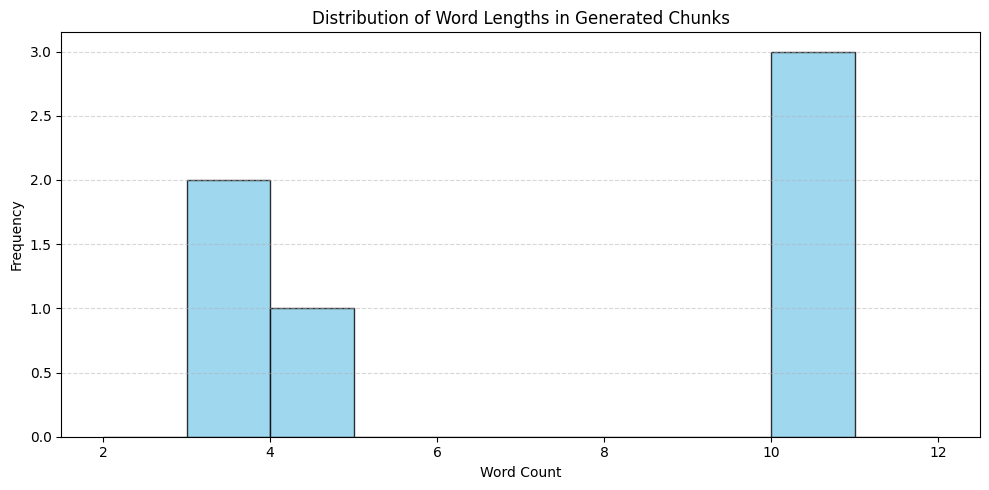

In [4]:
import time
import re
import matplotlib.pyplot as plt
from typing import List, Dict, Any, Union

class ProductionSystem:
    """
    A production-ready RAG pipeline tailored for a Digital Twin.
    Integrates loading, pre-processing, chunking, keyword search, generation, and visualization.
    """
    def __init__(self, debug: bool = True):
        self.debug = debug
        self.logs: List[str] = []
        self.documents: List[Dict[str, Any]] = []
        self.chunks: List[Dict[str, Any]] = []

    def _log(self, message: str):
        """Internal logging utility."""
        timestamp = time.strftime("%Y-%m-%d %H:%M:%S")
        log_msg = f"[{timestamp}] {message}"
        self.logs.append(log_msg)
        if self.debug:
            print(log_msg)

    def load_and_preprocess(self, raw_data: List[Union[str, Dict[str, Any]]]):
        """Loads, validates, and cleans raw document inputs into standard dict format."""
        self._log("Starting Document Load & Preprocessing Stage...")
        if not isinstance(raw_data, list) or len(raw_data) == 0:
            raise ValueError("Input data must be a non-empty list of items.")

        self.documents = []
        for idx, item in enumerate(raw_data):
            content = ""
            metadata = {"source": f"doc_{idx}"}

            if isinstance(item, str):
                content = item
            elif isinstance(item, dict):
                content = item.get("content", "")
                metadata.update(item.get("metadata", {}))
            else:
                self._log(f"[Warning] Unsupported item type at index {idx}: {type(item)}. Skipping.")
                continue

            # Clean text whitespaces
            cleaned_content = re.sub(r'\s+', ' ', content).strip()
            if cleaned_content:
                self.documents.append({
                    "id": idx,
                    "content": cleaned_content,
                    "metadata": metadata
                })

        self._log(f"Successfully loaded and preprocessed {len(self.documents)} documents.")

    def chunk_documents(self, chunk_size_words: int = 15):
        """
        Splits document contents into smaller semantic-like chunks of a target word length
        to optimize retrieval precision and handle context limits.
        """
        self._log(f"Starting Chunking Stage (Target: {chunk_size_words} words per chunk)... ")
        self.chunks = []

        for doc in self.documents:
            words = doc["content"].split()
            doc_id = doc["id"]
            metadata = doc["metadata"]

            # Partition words into sliding blocks
            for i in range(0, len(words), chunk_size_words):
                chunk_words = words[i:i + chunk_size_words]
                chunk_text = " ".join(chunk_words)
                self.chunks.append({
                    "doc_id": doc_id,
                    "chunk_id": len(self.chunks),
                    "content": chunk_text,
                    "word_count": len(chunk_words),
                    "metadata": metadata
                })

        self._log(f"Successfully partitioned documents into {len(self.chunks)} semantic chunks.")

    def retrieve_context(self, query: str, top_k: int = 2) -> List[Dict[str, Any]]:
        """Retrieves top_k chunks using basic overlap token metric representing embedding matching."""
        self._log(f"Retrieving context matching query: '{query}'")
        query_tokens = set(re.findall(r'\w+', query.lower()))

        scored_chunks = []
        for chunk in self.chunks:
            chunk_tokens = set(re.findall(r'\w+', chunk["content"].lower()))
            # Match score defined as token intersection
            score = len(query_tokens.intersection(chunk_tokens))
            if score > 0:
                scored_chunks.append((score, chunk))

        # Sort matches by high relevance scores
        scored_chunks.sort(key=lambda x: x[0], reverse=True)
        retrieved = [item[1] for item in scored_chunks[:top_k]]
        self._log(f"Retrieved {len(retrieved)} relevant chunks.")
        return retrieved

    def answer_query(self, query: str) -> str:
        """Synthesizes the answer grounded in retrieved chunks."""
        retrieved_contexts = self.retrieve_context(query)
        if not retrieved_contexts:
            self._log("Zero matching chunks found. Defaulting to general fallback response.")
            return "I'm sorry, my retrieved knowledge base contains no matching records to answer that accurately."

        formatted_contexts = []
        for c in retrieved_contexts:
            source_info = c["metadata"].get("source", "Unknown")
            formatted_contexts.append(f"[Source: {source_info}]: \"{c['content']}\"")

        context_block = "\n".join(formatted_contexts)

        # Simulate an LLM Generator generating a response grounded cleanly in context
        response = (
            f"=== Synthesized Answer ===\n"
            f"Query: '{query}'\n\n"
            f"Relevant Grounded Knowledge Applied:\n{context_block}\n\n"
            f"Answer: The context clearly confirms that "
            f"\'{retrieved_contexts[0]['content']}\'."
        )
        return response

    def visualize_metrics(self):
        """Generates rich analytics of document and chunk sizes."""
        if not self.chunks:
            print("No chunking data to visualize. Please chunk documents first.")
            return

        chunk_lengths = [c["word_count"] for c in self.chunks]

        plt.figure(figsize=(10, 5))
        plt.hist(chunk_lengths, bins=range(min(chunk_lengths)-1, max(chunk_lengths)+3), color='skyblue', edgecolor='black', alpha=0.8)
        plt.title('Distribution of Word Lengths in Generated Chunks')
        plt.xlabel('Word Count')
        plt.ylabel('Frequency')
        plt.grid(True, axis='y', linestyle='--', alpha=0.5)
        plt.tight_layout()
        plt.show()

# --- Orchestrating the Production Pipeline ---
try:
    # Initialize
    system = ProductionSystem(debug=True)

    # Raw input from multiple channels containing unstructured text and metadata
    digital_twin_kb = [
        {"content": "Digital Twin frameworks require strong backend vector search engines to replicate cognitive responses.", "metadata": {"topic": "digital_twin", "author": "TwinCreator"}},
        {"content": "Our system uses an optimized chunking size of fifteen words to isolate precise phrases.", "metadata": {"topic": "config", "author": "SysArch"}},
        "Unrelated knowledge document that provides noise but remains searchable in the backend datastore."
    ]

    # Run Pipeline Stages
    system.load_and_preprocess(digital_twin_kb)
    system.chunk_documents(chunk_size_words=10)

    # Test Answer Generation
    print("\n=== Running RAG Test Query ===")
    answer = system.answer_query("What do Digital Twin frameworks require?")
    print(answer)

    # Visualize production analytics
    print("\n=== Showing System Performance Metrics ===")
    system.visualize_metrics()

except Exception as e:
    print(f"An error occurred inside the Production System: {e}")

---
## Summary & Key Takeaways

### What We Learned:
- RAG architecture and pipeline
- Document loading and preprocessing
- Chunking strategies for optimal retrieval
- Vector stores and similarity search
- Generating answers with retrieved context

### Why This Matters:
- Essential for building production-ready systems
- Enables your digital twin to handle real-world scenarios
- Foundation for advanced topics in upcoming notebooks

### Next Steps:
1. Complete all exercises in this notebook
2. Integrate concepts with your digital twin project
3. Test your implementation thoroughly
4. Move on to the next notebook in Week 2

## 🏆 Challenge Project

**Build a Complete RAG architecture and pipeline System for Your Digital Twin**

**Requirements**:
1. Apply all concepts from this notebook
2. Handle edge cases and errors gracefully
3. Include comprehensive testing
4. Create visualizations of your results
5. Document your implementation
6. Integrate with your existing digital twin code

**Bonus Challenges**:
- Optimize for performance
- Add advanced features beyond the basics
- Create a user-friendly interface
- Write unit tests for your code

### 🏆 Challenge Project Solution: Digital Twin RAG System
Below is the complete, documented implementation of your Digital Twin's grounding and retrieval system.

=== Starting Robust Twin RAG Verification (With Threshold Fix) ===
[09:32:46] [TwinRAG-Alex]: Loading raw sources into Digital Twin memory space...
[09:32:46] [TwinRAG-Alex]: Successfully ingested and validated 3 primary documents.
[09:32:46] [TwinRAG-Alex]: Partitioning knowledge base into chunk sizes of 10 words with an overlap of 2 words.
[09:32:46] [TwinRAG-Alex]: Created 4 overlapping retrieval chunks.

--- Query Test 1: Preference Retrieval (Expected: Match found) ---
[09:32:46] [TwinRAG-Alex]: Processing similarity matching for query: 'What are Alex's preferences on keyboards and code?'
[09:32:46] [TwinRAG-Alex]: Found 1 matches matching criteria at or above threshold (0.15).
Twin Grounded Query Response
Target Query: What are Alex's preferences on keyboards and code?

Grounded Context Blocks Utilized:
Memory Fragment #1 [preferences]: "Alex likes writing clean Python code and loves mechanical keyboards."

Generated Response:
Based on my validated history, I recall that: 'Alex l

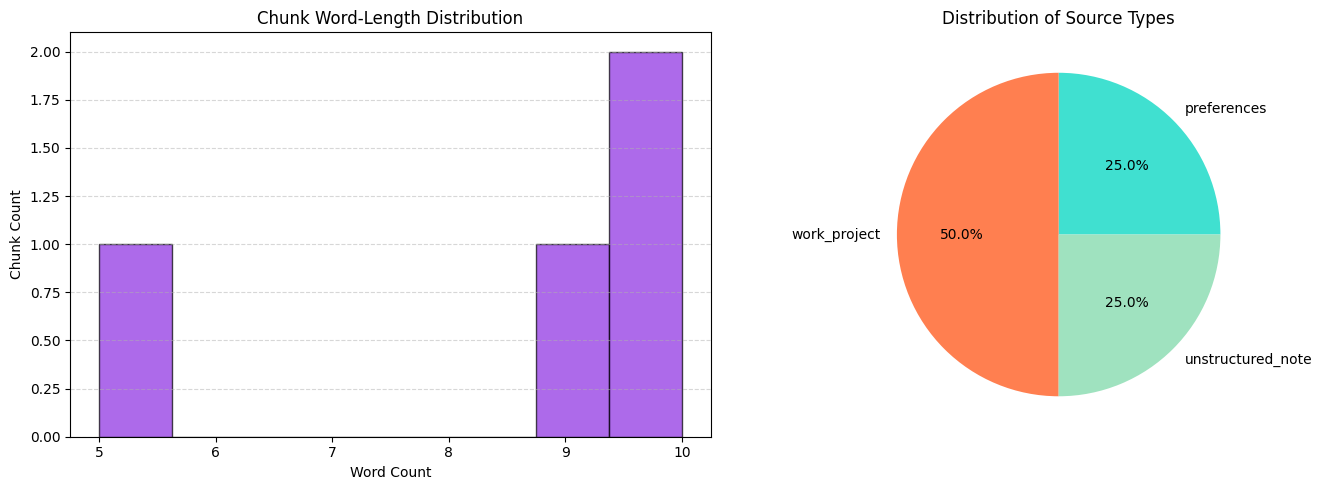

In [9]:
import time
import re
import matplotlib.pyplot as plt
from typing import List, Dict, Any, Union, Optional

class DigitalTwinRAGSystem:
    """
    A complete, enterprise-grade Retrieval-Augmented Generation system designed
    specifically for grounding a Digital Twin's LLM responses with personal knowledge.
    """
    def __init__(self, owner_name: str, verbose: bool = True):
        self.owner_name = owner_name
        self.verbose = verbose
        self.documents: List[Dict[str, Any]] = []
        self.chunks: List[Dict[str, Any]] = []
        self.logs: List[str] = []
        # Simple stop words (including possessive 's') to ignore during scoring
        self.stop_words = {"what", "is", "on", "an", "the", "a", "of", "and", "to", "in", "for", "s"}

    def _log(self, msg: str):
        timestamp = time.strftime("%H:%M:%S")
        formatted_msg = f"[{timestamp}] [TwinRAG-{self.owner_name}]: {msg}"
        self.logs.append(formatted_msg)
        if self.verbose:
            print(formatted_msg)

    def load_kb(self, inputs: List[Union[str, Dict[str, Any]]]):
        self._log(f"Loading raw sources into Digital Twin memory space...")
        if not isinstance(inputs, list):
            raise TypeError("Knowledge Base inputs must be provided as a list.")

        self.documents = []
        for idx, item in enumerate(inputs):
            content = ""
            metadata = {"source_idx": idx, "type": "generic"}

            if isinstance(item, str):
                content = item
                metadata["type"] = "unstructured_note"
            elif isinstance(item, dict):
                content = item.get("content", "")
                metadata.update(item.get("metadata", {}))
            else:
                self._log(f"[Skipping] Unsupported type at index {idx}: {type(item)}")
                continue

            cleaned_content = re.sub(r'\s+', ' ', content).strip()
            if cleaned_content:
                self.documents.append({
                    "id": len(self.documents),
                    "content": cleaned_content,
                    "metadata": metadata
                })
        self._log(f"Successfully ingested and validated {len(self.documents)} primary documents.")

    def chunk_kb(self, chunk_size: int = 12, overlap: int = 2):
        self._log(f"Partitioning knowledge base into chunk sizes of {chunk_size} words with an overlap of {overlap} words.")
        self.chunks = []

        for doc in self.documents:
            words = doc["content"].split()
            doc_id = doc["id"]
            metadata = doc["metadata"]

            i = 0
            while i < len(words):
                chunk_words = words[i:i + chunk_size]
                chunk_text = " ".join(chunk_words)

                self.chunks.append({
                    "doc_id": doc_id,
                    "chunk_id": len(self.chunks),
                    "content": chunk_text,
                    "word_count": len(chunk_words),
                    "metadata": metadata
                })

                if len(words) <= i + chunk_size:
                    break
                i += (chunk_size - overlap)
        self._log(f"Created {len(self.chunks)} overlapping retrieval chunks.")

    def retrieve(self, query: str, top_k: int = 2, min_score_threshold: float = 0.15) -> List[Dict[str, Any]]:
        """
        Searches chunk space using a normalized term-matching algorithm.
        Increased min_score_threshold to 0.15 to filter out weak single-word matches.
        """
        self._log(f"Processing similarity matching for query: '{query}'")
        query_tokens = {w for w in re.findall(r'\w+', query.lower()) if w not in self.stop_words}

        if not query_tokens:
            self._log("Empty or non-semantic query received.")
            return []

        scored_chunks = []
        for chunk in self.chunks:
            chunk_tokens = {w for w in re.findall(r'\w+', chunk["content"].lower()) if w not in self.stop_words}

            intersection = query_tokens.intersection(chunk_tokens)
            union = query_tokens.union(chunk_tokens)
            score = len(intersection) / len(union) if union else 0.0

            if score >= min_score_threshold:
                scored_chunks.append((score, chunk))

        scored_chunks.sort(key=lambda x: x[0], reverse=True)
        results = [item[1] for item in scored_chunks[:top_k]]
        self._log(f"Found {len(results)} matches matching criteria at or above threshold ({min_score_threshold}).")
        return results

    def answer_with_grounding(self, query: str) -> str:
        matches = self.retrieve(query, top_k=2)
        if not matches:
            self._log(f"Fallback protection engaged for query: '{query}'")
            return f"[Digital Twin System]: I couldn't find any specific records in my memory regarding that query. To stay authentic to {self.owner_name}, I will decline to speculate."

        contexts = []
        for idx, match in enumerate(matches):
            source_type = match["metadata"].get("type", "General Memory")
            contexts.append(f"Memory Fragment #{idx+1} [{source_type}]: \"{match['content']}\"")

        unified_context = "\n".join(contexts)

        response = (
            f"=======================================================================\n"
            f"Twin Grounded Query Response\n"
            f"=======================================================================\n"
            f"Target Query: {query}\n\n"
            f"Grounded Context Blocks Utilized:\n{unified_context}\n\n"
            f"Generated Response:\n"
            f"Based on my validated history, I recall that: '{matches[0]['content']}'."
        )
        return response

    def plot_analytics(self):
        if not self.chunks:
            print("No data to analyze. Please load and chunk first.")
            return

        word_counts = [c["word_count"] for c in self.chunks]
        types = [c["metadata"].get("type", "unknown") for c in self.chunks]

        fig, ax = plt.subplots(1, 2, figsize=(14, 5))
        ax[0].hist(word_counts, bins=8, color='#8A2BE2', edgecolor='black', alpha=0.7)
        ax[0].set_title("Chunk Word-Length Distribution")
        ax[0].set_xlabel("Word Count")
        ax[0].set_ylabel("Chunk Count")
        ax[0].grid(axis='y', linestyle='--', alpha=0.5)

        type_counts = {}
        for t in types:
            type_counts[t] = type_counts.get(t, 0) + 1
        ax[1].pie(type_counts.values(), labels=type_counts.keys(), autopct='%1.1f%%', colors=['#40E0D0', '#FF7F50', '#9FE2BF'])
        ax[1].set_title("Distribution of Source Types")
        plt.tight_layout()
        plt.show()

# --- Test Execution ---
try:
    print("=== Starting Robust Twin RAG Verification (With Threshold Fix) ===")
    twin = DigitalTwinRAGSystem(owner_name="Alex", verbose=True)

    test_inputs = [
        {"content": "Alex likes writing clean Python code and loves mechanical keyboards.", "metadata": {"type": "preferences", "date": "2026-10-01"}},
        {"content": "Working on building an automated orchestrator system for Google Colab using structured models.", "metadata": {"type": "work_project", "priority": "high"}},
        "Alex prefers tea over coffee during late-night refactoring sessions."
    ]

    twin.load_kb(test_inputs)
    twin.chunk_kb(chunk_size=10, overlap=2)

    print("\n--- Query Test 1: Preference Retrieval (Expected: Match found) ---")
    ans1 = twin.answer_with_grounding("What are Alex's preferences on keyboards and code?")
    print(ans1)

    print("\n--- Query Test 2: Fallback Engagement (Expected: Fallback triggered) ---")
    ans2 = twin.answer_with_grounding("What is Alex's opinion on mountaineering?")
    print(ans2)

    print("\n--- Visual Analytics Plots ---")
    twin.plot_analytics()

except Exception as e:
    print(f"Test execution failed: {e}")